# Project Overview

# Load Dataset

In [2]:
from google.colab import files

uploaded = files.upload()

Saving customer_support_tickets.csv to customer_support_tickets.csv


# Import Libraries

In [3]:
import pandas as pd

df = pd.read_csv('customer_support_tickets.csv')

df.head()

,Ticket_ID,Customer_ID,Created_Date,Customer_Type,Product,Issue_Type,Channel,Priority,Agent_ID,First_Response_Minutes,Resolution_Time_Hours,Customer_Tenure_Months,Previous_Tickets,Customer_Satisfaction,Escalated,Reopened
0,TKT00001,CUST1860,2025-07-12 07:36:38,Individual,CRM,Integration,Web Form,Medium,AG025,64.5,19.8,17.0,9,3.0,No,No
1,TKT00002,CUST2294,2025-12-15 18:43:56,Enterprise,CRM,Account Setup,Web Form,Low,AG049,45.9,3.2,29.0,5,3.0,Yes,No
2,TKT00003,CUST2130,2025-12-23 11:06:10,Enterprise,Billing,Login Issue,Chat,Low,AG001,11.4,4.0,37.0,5,4.0,No,No
3,TKT00004,CUST2095,2025-10-22 16:30:06,Individual,API,Account Setup,Email,Low,AG036,79.6,5.1,23.0,5,4.0,No,No
4,TKT00005,CUST2638,2025-11-02 11:49:20,SMB,Analytics,Login Issue,Chat,Low,AG018,12.6,3.0,8.0,4,5.0,No,No


# Data Understanding

In [4]:
df.shape

(10015, 16)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10015 entries, 0 to 10014
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Ticket_ID               10015 non-null  object 
 1   Customer_ID             10015 non-null  object 
 2   Created_Date            10015 non-null  object 
 3   Customer_Type           10015 non-null  object 
 4   Product                 10015 non-null  object 
 5   Issue_Type              10015 non-null  object 
 6   Channel                 10015 non-null  object 
 7   Priority                10015 non-null  object 
 8   Agent_ID                10015 non-null  object 
 9   First_Response_Minutes  9915 non-null   float64
 10  Resolution_Time_Hours   10015 non-null  float64
 11  Customer_Tenure_Months  9914 non-null   float64
 12  Previous_Tickets        10015 non-null  int64  
 13  Customer_Satisfaction   9865 non-null   float64
 14  Escalated               10015 non-null

In [6]:
df.isnull().sum()

,0
Ticket_ID,0
Customer_ID,0
Created_Date,0
Customer_Type,0
Product,0
Issue_Type,0
Channel,0
Priority,0
Agent_ID,0
First_Response_Minutes,100


# Data Cleaning

In [7]:
df.duplicated().sum()

np.int64(15)

In [8]:
categorical_columns = [
    'Customer_Type',
    'Product',
    'Issue_Type',
    'Channel',
    'Priority',
    'Escalated',
    'Reopened'
]

for col in categorical_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())


--- Customer_Type ---
Customer_Type
SMB           3754
Enterprise    2118
Startup       2088
Individual    2055
Name: count, dtype: int64

--- Product ---
Product
CRM              3034
Analytics        2015
Billing          1869
Collaboration    1672
API              1425
Name: count, dtype: int64

--- Issue_Type ---
Issue_Type
Bug                1790
Login Issue        1618
Integration        1323
Payment Issue      1214
Performance        1071
Feature Request    1003
Account Setup       999
Data Issue          997
Name: count, dtype: int64

--- Channel ---
Channel
Email       3562
Chat        2965
Phone       1990
Web Form    1498
Name: count, dtype: int64

--- Priority ---
Priority
Low       7540
Medium    2072
High       403
Name: count, dtype: int64

--- Escalated ---
Escalated
No     9342
Yes     673
Name: count, dtype: int64

--- Reopened ---
Reopened
No     9404
Yes     611
Name: count, dtype: int64


In [9]:
numerical_columns = [
    'First_Response_Minutes',
    'Resolution_Time_Hours',
    'Customer_Tenure_Months',
    'Previous_Tickets',
    'Customer_Satisfaction'
]

df[numerical_columns].describe()

,First_Response_Minutes,Resolution_Time_Hours,Customer_Tenure_Months,Previous_Tickets,Customer_Satisfaction
count,9915.000000,10015.000000,9914.000000,10015.000000,9865.000000
mean,30.926051,11.832921,25.072221,3.955866,3.890826
std,23.633751,7.437165,15.303956,1.982359,0.686256
min,2.000000,0.500000,1.000000,0.000000,2.000000
25%,10.100000,5.200000,14.000000,3.000000,3.000000
50%,19.400000,10.900000,22.000000,4.000000,4.000000
75%,50.300000,17.000000,34.000000,5.000000,4.000000
max,110.600000,41.900000,72.000000,16.000000,5.000000


In [10]:
duplicates = df[df.duplicated(keep=False)]

duplicates.sort_values('Ticket_ID').head(30)

,Ticket_ID,Customer_ID,Created_Date,Customer_Type,Product,Issue_Type,Channel,Priority,Agent_ID,First_Response_Minutes,Resolution_Time_Hours,Customer_Tenure_Months,Previous_Tickets,Customer_Satisfaction,Escalated,Reopened
439,TKT00440,CUST1011,2025-02-05 08:37:48,SMB,Analytics,Performance,Chat,Low,AG020,6.9,14.2,42.0,4,4.0,No,No
10009,TKT00440,CUST1011,2025-02-05 08:37:48,SMB,Analytics,Performance,Chat,Low,AG020,6.9,14.2,42.0,4,4.0,No,No
576,TKT00577,CUST2035,2025-02-27 13:26:38,Startup,Analytics,Login Issue,Email,Low,AG013,32.9,5.2,22.0,3,4.0,No,No
10006,TKT00577,CUST2035,2025-02-27 13:26:38,Startup,Analytics,Login Issue,Email,Low,AG013,32.9,5.2,22.0,3,4.0,No,No
1731,TKT01732,CUST1918,2025-02-15 10:48:08,Individual,Billing,Login Issue,Email,Low,AG048,53.1,2.7,18.0,2,5.0,No,No
10002,TKT01732,CUST1918,2025-02-15 10:48:08,Individual,Billing,Login Issue,Email,Low,AG048,53.1,2.7,18.0,2,5.0,No,No
2750,TKT02751,CUST1504,2025-06-27 12:10:42,SMB,Collaboration,Feature Request,Chat,Low,AG023,12.8,13.6,NaN,4,3.0,No,Yes
10010,TKT02751,CUST1504,2025-06-27 12:10:42,SMB,Collaboration,Feature Request,Chat,Low,AG023,12.8,13.6,NaN,4,3.0,No,Yes
10014,TKT04000,CUST1643,2025-04-07 22:24:25,Startup,Analytics,Performance,Chat,Low,AG050,8.9,20.4,7.0,6,3.0,No,No
3999,TKT04000,CUST1643,2025-04-07 22:24:25,Startup,Analytics,Performance,Chat,Low,AG050,8.9,20.4,7.0,6,3.0,No,No


In [11]:
df['Ticket_ID'].duplicated().sum()

np.int64(15)

In [12]:
df['Customer_ID'].nunique()

2452

In [13]:
print("Minimum date:", df['Created_Date'].min())
print("Maximum date:", df['Created_Date'].max())

Minimum date: 2025-01-01 00:53:32
Maximum date: 2025-12-30 23:43:11


# Data Cleaning

In [14]:
df_clean = df.copy()

print("Original rows:", len(df))
print("Working rows:", len(df_clean))

Original rows: 10015
Working rows: 10015


In [15]:
df_clean = df_clean.drop_duplicates()

print("Rows after removing duplicates:", len(df_clean))
print("Duplicates remaining:", df_clean.duplicated().sum())

Rows after removing duplicates: 10000
Duplicates remaining: 0


In [16]:
df_clean['Created_Date'] = pd.to_datetime(df_clean['Created_Date'])

df_clean['Created_Date'].dtype

dtype('<M8[ns]')

In [17]:
df_clean[df_clean['First_Response_Minutes'].isnull()]['Priority'].value_counts()

,count
Priority,
Low,79
Medium,20
High,1


In [18]:
df_clean[df_clean['Customer_Tenure_Months'].isnull()]['Customer_Type'].value_counts()

,count
Customer_Type,
SMB,35
Startup,31
Individual,18
Enterprise,16


In [19]:
df_clean[df_clean['Customer_Satisfaction'].isnull()]['Priority'].value_counts()

,count
Priority,
Low,114
Medium,30
High,6


Handle the missing values

In [20]:
print("First Response Median:",
      df_clean['First_Response_Minutes'].median())

print("Customer Tenure Median:",
      df_clean['Customer_Tenure_Months'].median())

print("Customer Satisfaction Median:",
      df_clean['Customer_Satisfaction'].median())

First Response Median: 19.4
Customer Tenure Median: 22.0
Customer Satisfaction Median: 4.0


Fill missing values

In [21]:
df_clean['First_Response_Minutes'] = df_clean['First_Response_Minutes'].fillna(
    df_clean['First_Response_Minutes'].median()
)

df_clean['Customer_Tenure_Months'] = df_clean['Customer_Tenure_Months'].fillna(
    df_clean['Customer_Tenure_Months'].median()
)

df_clean['Customer_Satisfaction'] = df_clean['Customer_Satisfaction'].fillna(
    df_clean['Customer_Satisfaction'].median()
)

In [22]:
df_clean.isnull().sum()

,0
Ticket_ID,0
Customer_ID,0
Created_Date,0
Customer_Type,0
Product,0
Issue_Type,0
Channel,0
Priority,0
Agent_ID,0
First_Response_Minutes,0


In [23]:
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])
print("Duplicate rows:", df_clean.duplicated().sum())
print("Missing values:", df_clean.isnull().sum().sum())

Rows: 10000
Columns: 16
Duplicate rows: 0
Missing values: 0


In [24]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Ticket_ID               10000 non-null  object        
 1   Customer_ID             10000 non-null  object        
 2   Created_Date            10000 non-null  datetime64[ns]
 3   Customer_Type           10000 non-null  object        
 4   Product                 10000 non-null  object        
 5   Issue_Type              10000 non-null  object        
 6   Channel                 10000 non-null  object        
 7   Priority                10000 non-null  object        
 8   Agent_ID                10000 non-null  object        
 9   First_Response_Minutes  10000 non-null  float64       
 10  Resolution_Time_Hours   10000 non-null  float64       
 11  Customer_Tenure_Months  10000 non-null  float64       
 12  Previous_Tickets        10000 non-null  int64       

In [25]:
df_clean.to_csv('customer_support_tickets_cleaned.csv', index=False)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


In [26]:
print("Total Tickets:", len(df_clean))
print("Total Customers:", df_clean['Customer_ID'].nunique())
print("Total Products:", df_clean['Product'].nunique())
print("Total Issue Types:", df_clean['Issue_Type'].nunique())
print("Total Agents:", df_clean['Agent_ID'].nunique())

print("\nAverage First Response Time:",
      round(df_clean['First_Response_Minutes'].mean(), 2), "minutes")

print("Average Resolution Time:",
      round(df_clean['Resolution_Time_Hours'].mean(), 2), "hours")

print("Average Customer Satisfaction:",
      round(df_clean['Customer_Satisfaction'].mean(), 2), "/ 5")

Total Tickets: 10000
Total Customers: 2452
Total Products: 5
Total Issue Types: 8
Total Agents: 50

Average First Response Time: 30.82 minutes
Average Resolution Time: 11.84 hours
Average Customer Satisfaction: 3.89 / 5


In [27]:
priority_counts = df_clean['Priority'].value_counts()

print(priority_counts)

Priority
Low       7527
Medium    2070
High       403
Name: count, dtype: int64


In [28]:
priority_percentage = (
    df_clean['Priority']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(priority_percentage)

Priority
Low       75.27
Medium    20.70
High       4.03
Name: proportion, dtype: float64


# Business Insights

# What is the distribution of support tickets across priority levels?

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

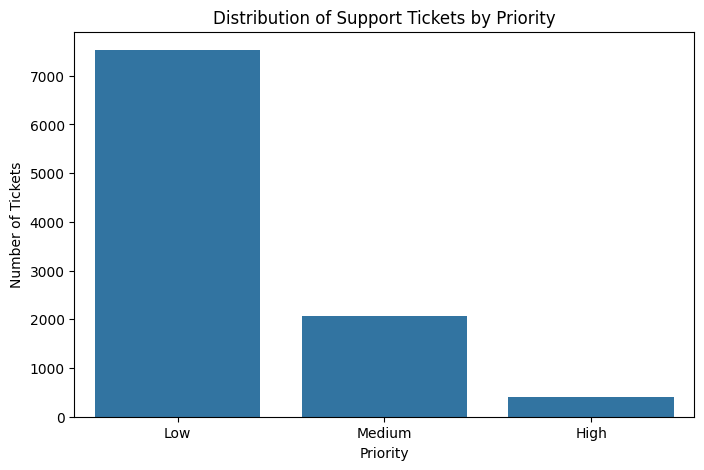

In [30]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x='Priority',
    order=['Low', 'Medium', 'High']
)

plt.title('Distribution of Support Tickets by Priority')
plt.xlabel('Priority')
plt.ylabel('Number of Tickets')

plt.show()

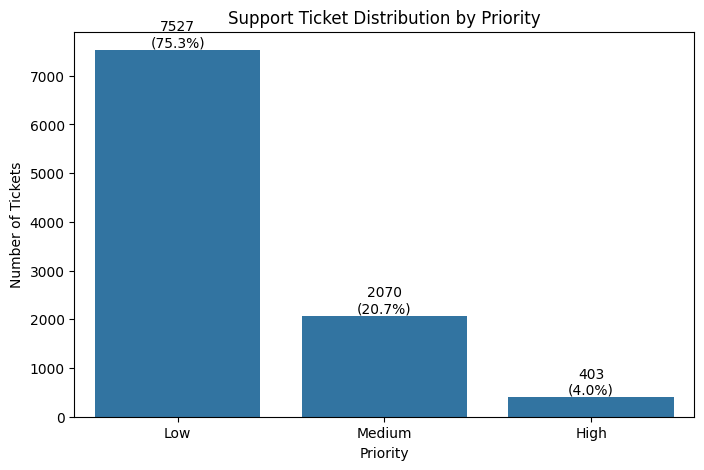

In [31]:
priority_counts = df_clean['Priority'].value_counts()

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df_clean,
    x='Priority',
    order=['Low', 'Medium', 'High']
)

total = len(df_clean)

for container in ax.containers:
    labels = [
        f'{int(value)}\n({value / total * 100:.1f}%)'
        for value in container.datavalues
    ]
    ax.bar_label(container, labels=labels)

plt.title('Support Ticket Distribution by Priority')
plt.xlabel('Priority')
plt.ylabel('Number of Tickets')

plt.show()

# Which issue types generate the most support tickets?

In [32]:
issue_counts = df_clean['Issue_Type'].value_counts()

print(issue_counts)

Issue_Type
Bug                1788
Login Issue        1613
Integration        1322
Payment Issue      1214
Performance        1069
Feature Request    1000
Account Setup       998
Data Issue          996
Name: count, dtype: int64


In [33]:
issue_percentage = (
    df_clean['Issue_Type']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(issue_percentage)

Issue_Type
Bug                17.88
Login Issue        16.13
Integration        13.22
Payment Issue      12.14
Performance        10.69
Feature Request    10.00
Account Setup       9.98
Data Issue          9.96
Name: proportion, dtype: float64


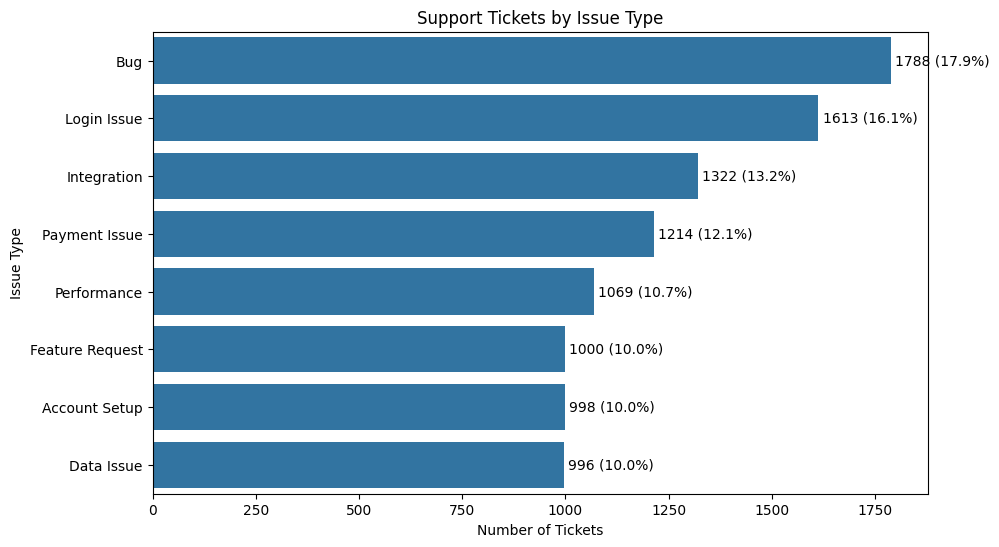

In [34]:
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=df_clean,
    y='Issue_Type',
    order=df_clean['Issue_Type'].value_counts().index
)

total = len(df_clean)

for container in ax.containers:
    labels = [
        f'{int(value)} ({value / total * 100:.1f}%)'
        for value in container.datavalues
    ]
    ax.bar_label(container, labels=labels, padding=3)

plt.title('Support Tickets by Issue Type')
plt.xlabel('Number of Tickets')
plt.ylabel('Issue Type')
plt.show()

# Which products generate the most support demand?

In [35]:
product_counts = df_clean['Product'].value_counts()

print(product_counts)

Product
CRM              3029
Analytics        2011
Billing          1865
Collaboration    1671
API              1424
Name: count, dtype: int64


In [36]:
product_percentage = (
    df_clean['Product']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(product_percentage)

Product
CRM              30.29
Analytics        20.11
Billing          18.65
Collaboration    16.71
API              14.24
Name: proportion, dtype: float64


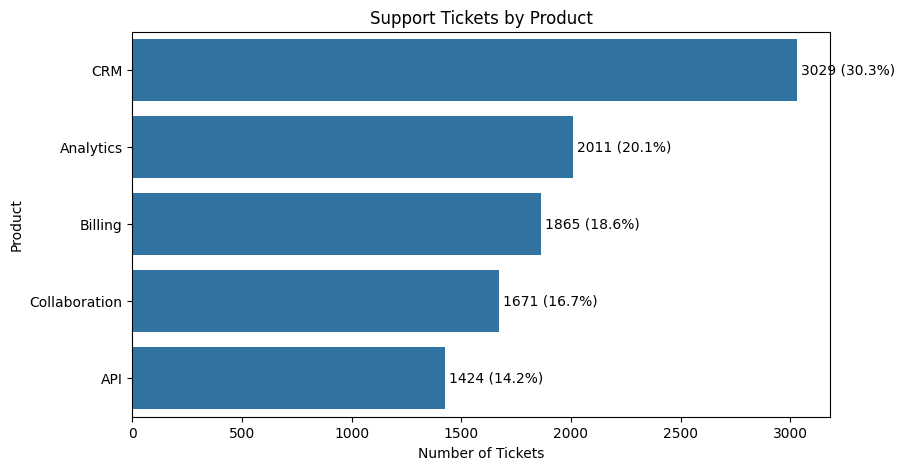

In [37]:
plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=df_clean,
    y='Product',
    order=df_clean['Product'].value_counts().index
)

total = len(df_clean)

for container in ax.containers:
    labels = [
        f'{int(value)} ({value / total * 100:.1f}%)'
        for value in container.datavalues
    ]
    ax.bar_label(container, labels=labels, padding=3)

plt.title('Support Tickets by Product')
plt.xlabel('Number of Tickets')
plt.ylabel('Product')
plt.show()

# Which types of issues are driving support demand for each product?

In [38]:
product_issue = pd.crosstab(
    df_clean['Product'],
    df_clean['Issue_Type']
)

print(product_issue)

Issue_Type     Account Setup  Bug  Data Issue  Feature Request  Integration  \
Product                                                                       
API                      147  234         149              157          196   
Analytics                223  326         213              185          278   
Billing                  179  357         198              175          232   
CRM                      286  549         292              313          391   
Collaboration            163  322         144              170          225   

Issue_Type     Login Issue  Payment Issue  Performance  
Product                                                 
API                    232            155          154  
Analytics              347            241          198  
Billing                286            222          216  
CRM                    497            380          321  
Collaboration          251            216          180  


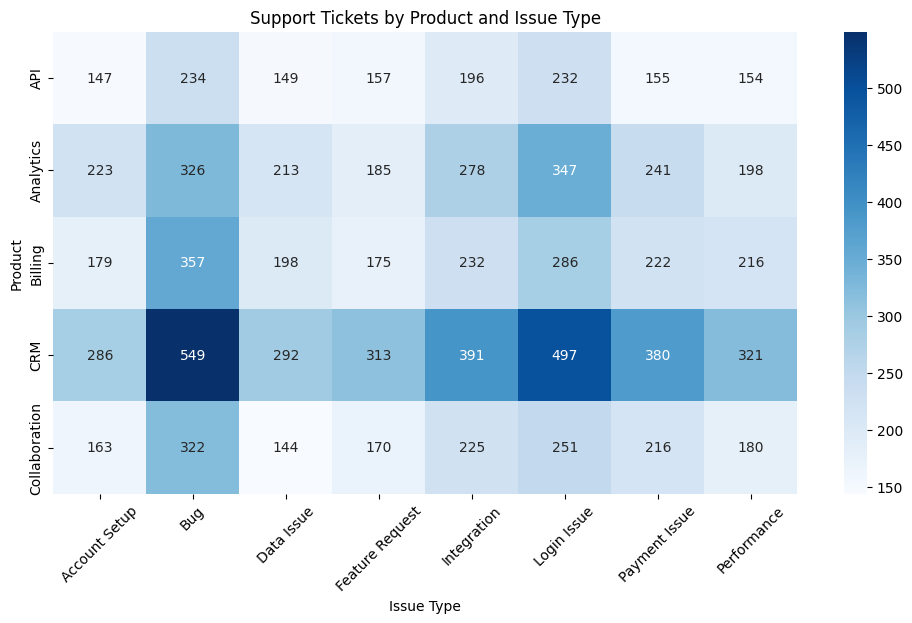

In [39]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    product_issue,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Support Tickets by Product and Issue Type')
plt.xlabel('Issue Type')
plt.ylabel('Product')
plt.xticks(rotation=45)
plt.show()

# Are certain issue types associated with a higher proportion of High-priority tickets?

In [40]:
issue_priority = pd.crosstab(
    df_clean['Issue_Type'],
    df_clean['Priority']
)

print(issue_priority)

Priority         High   Low  Medium
Issue_Type                         
Account Setup       2   907      89
Bug               121  1228     439
Data Issue         30   755     211
Feature Request    72   624     304
Integration       104   797     421
Login Issue         6  1463     144
Payment Issue      16   977     221
Performance        52   776     241


In [41]:
issue_priority_pct = pd.crosstab(
    df_clean['Issue_Type'],
    df_clean['Priority'],
    normalize='index'
).mul(100).round(2)

print(issue_priority_pct)

Priority         High    Low  Medium
Issue_Type                          
Account Setup    0.20  90.88    8.92
Bug              6.77  68.68   24.55
Data Issue       3.01  75.80   21.18
Feature Request  7.20  62.40   30.40
Integration      7.87  60.29   31.85
Login Issue      0.37  90.70    8.93
Payment Issue    1.32  80.48   18.20
Performance      4.86  72.59   22.54


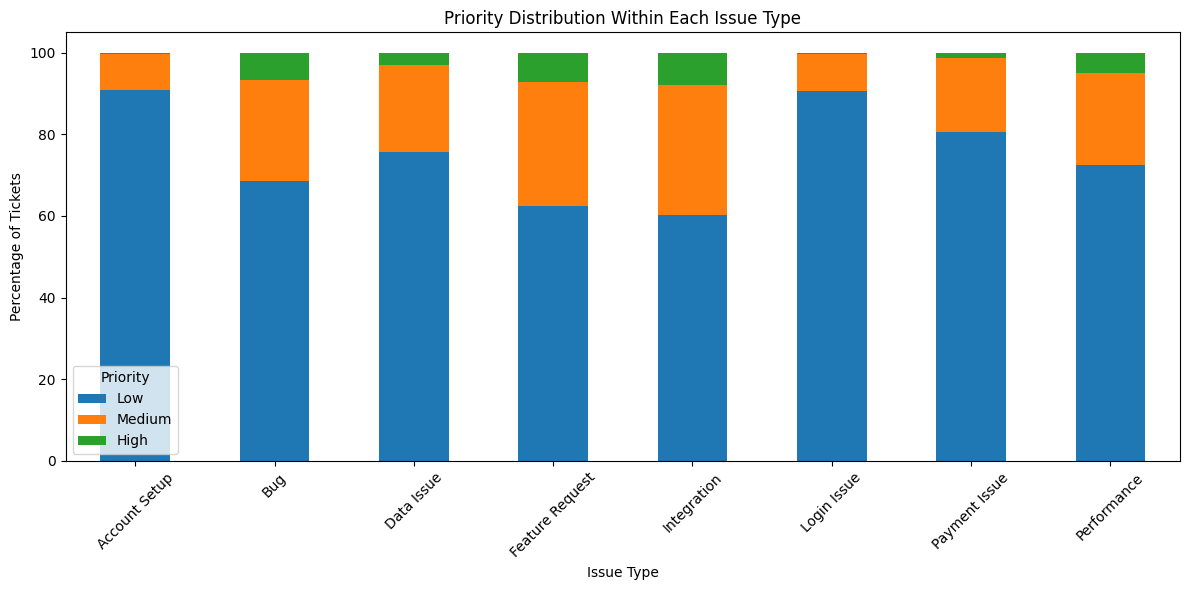

In [42]:
issue_priority_pct[['Low', 'Medium', 'High']].plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

plt.title('Priority Distribution Within Each Issue Type')
plt.xlabel('Issue Type')
plt.ylabel('Percentage of Tickets')
plt.legend(title='Priority')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Which support channels generate the most tickets?

In [43]:
channel_counts = df_clean['Channel'].value_counts()

print(channel_counts)

Channel
Email       3555
Chat        2960
Phone       1987
Web Form    1498
Name: count, dtype: int64


In [44]:
channel_percentage = (
    df_clean['Channel']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(channel_percentage)

Channel
Email       35.55
Chat        29.60
Phone       19.87
Web Form    14.98
Name: proportion, dtype: float64


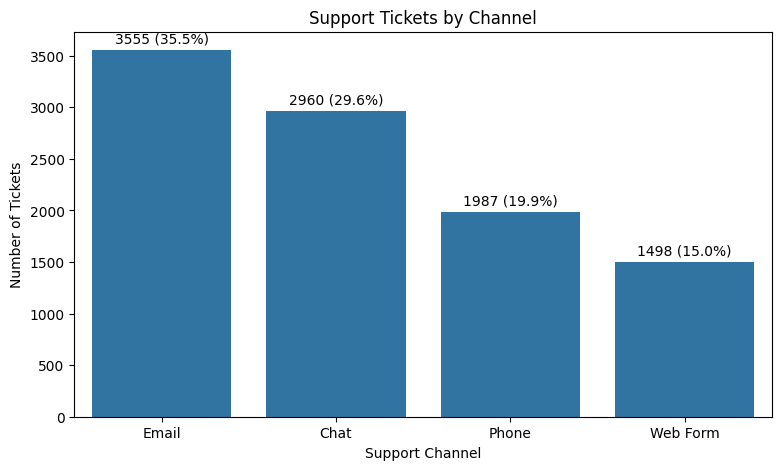

In [45]:
plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=df_clean,
    x='Channel',
    order=df_clean['Channel'].value_counts().index
)

total = len(df_clean)

for container in ax.containers:
    labels = [
        f'{int(value)} ({value / total * 100:.1f}%)'
        for value in container.datavalues
    ]
    ax.bar_label(container, labels=labels, padding=3)

plt.title('Support Tickets by Channel')
plt.xlabel('Support Channel')
plt.ylabel('Number of Tickets')
plt.show()

# Which customer type generates the most tickets?

In [46]:
customer_type_counts = df_clean['Customer_Type'].value_counts()

print(customer_type_counts)

Customer_Type
SMB           3749
Enterprise    2118
Startup       2083
Individual    2050
Name: count, dtype: int64


In [47]:
customer_type_percentage = (
    df_clean['Customer_Type']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(customer_type_percentage)

Customer_Type
SMB           37.49
Enterprise    21.18
Startup       20.83
Individual    20.50
Name: proportion, dtype: float64


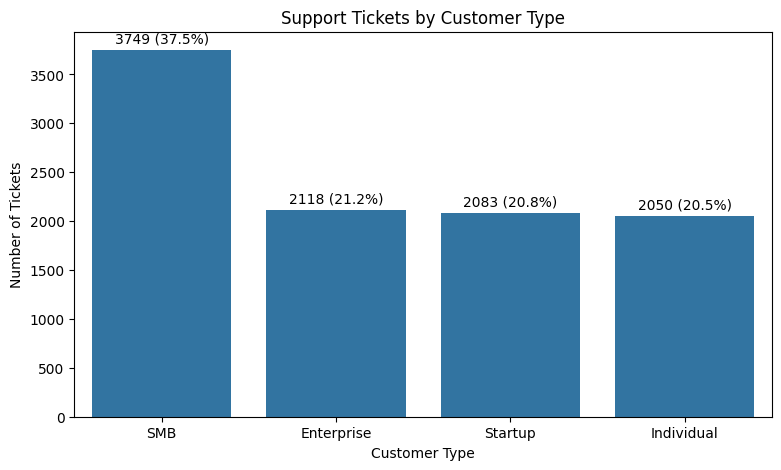

In [48]:
plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=df_clean,
    x='Customer_Type',
    order=df_clean['Customer_Type'].value_counts().index
)

total = len(df_clean)

for container in ax.containers:
    labels = [
        f'{int(value)} ({value / total * 100:.1f}%)'
        for value in container.datavalues
    ]
    ax.bar_label(container, labels=labels, padding=3)

plt.title('Support Tickets by Customer Type')
plt.xlabel('Customer Type')
plt.ylabel('Number of Tickets')
plt.show()

# Which Issue Types Take the Longest to Resolve?

In [49]:
issue_resolution = (
    df_clean.groupby('Issue_Type')['Resolution_Time_Hours']
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

print(issue_resolution)

Issue_Type
Integration        19.92
Feature Request    18.15
Performance        16.15
Bug                14.20
Data Issue         12.17
Payment Issue       7.01
Account Setup       4.98
Login Issue         3.48
Name: Resolution_Time_Hours, dtype: float64


In [50]:
issue_resolution_median = (
    df_clean.groupby('Issue_Type')['Resolution_Time_Hours']
    .median()
    .sort_values(ascending=False)
    .round(2)
)

print(issue_resolution_median)

Issue_Type
Integration        19.8
Feature Request    17.9
Performance        16.2
Bug                14.3
Data Issue         12.2
Payment Issue       6.9
Account Setup       4.9
Login Issue         3.5
Name: Resolution_Time_Hours, dtype: float64


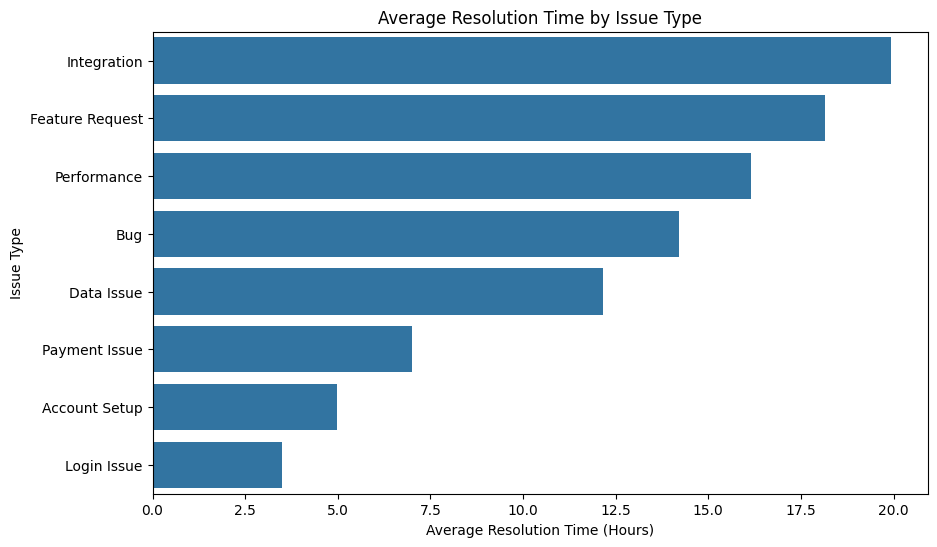

In [51]:
plt.figure(figsize=(10, 6))

resolution_order = (
    df_clean.groupby('Issue_Type')['Resolution_Time_Hours']
    .mean()
    .sort_values(ascending=False)
    .index
)

ax = sns.barplot(
    data=df_clean,
    x='Resolution_Time_Hours',
    y='Issue_Type',
    order=resolution_order,
    estimator='mean',
    errorbar=None
)

plt.title('Average Resolution Time by Issue Type')
plt.xlabel('Average Resolution Time (Hours)')
plt.ylabel('Issue Type')
plt.show()

What this tells us

1. Integration tickets take the longest to resolve.
Average resolution time is 19.92 hours, with a median of 19.8 hours.

2. Feature Requests are also relatively time-consuming.
They take around 18.15 hours on average.

3. Performance issues take about 16.15 hours.

4. Login Issues are resolved the fastest.
Average is only 3.48 hours.

Important analyst observation

The mean and median are very close for almost every issue type.

For example:

Integration → Mean: 19.92 hrs, Median: 19.8 hrs

That suggests the average isn't being heavily distorted by a few extremely large resolution times. So this finding is fairly consistent across the dataset.

Also notice something interesting from our previous analysis:

Integration had the highest High-priority percentage (7.87%) AND the highest resolution time (19.92 hrs).

That makes Integration worth investigating further. But we should not yet conclude that Integration is the biggest business problem because we still need to look at things like escalation, reopening and customer satisfaction.

### Insight

Integration tickets had the highest average resolution time at 19.92 hours, followed by Feature Requests at 18.15 hours and Performance issues at 16.15 hours. Login Issues had the lowest average resolution time at 3.48 hours.

The mean and median resolution times were very similar across issue types, indicating that the pattern was relatively consistent and not strongly driven by extreme values.

Integration also had the highest proportion of High-priority tickets in the earlier analysis, making it an important category for further investigation.

# Which products have the longest average resolution time?

In [52]:
product_resolution = (
    df_clean.groupby('Product')['Resolution_Time_Hours']
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

print(product_resolution)

Product
Collaboration    12.07
API              11.91
Billing          11.89
CRM              11.82
Analytics        11.56
Name: Resolution_Time_Hours, dtype: float64


# What we can say

1. Collaboration has the highest average resolution time at 12.07 hours.

2. Analytics has the lowest at 11.56 hours.

3. The difference is quite small.

The gap between the highest and lowest is only:

12.07 − 11.56 = 0.51 hours, which is about 31 minutes.

So unlike the issue-type analysis, product does not appear to create a large difference in resolution time in this dataset.

This is actually a good analyst observation. We shouldn't force a dramatic conclusion when the numbers are close.

One interesting comparison

Earlier we found:

CRM = 30.29% of all tickets, the highest volume.
CRM resolution time = 11.82 hours.
Collaboration has slightly longer resolution time = 12.07 hours, despite having fewer tickets.

So:

Highest ticket volume ≠ highest resolution time.

### Insight

Collaboration tickets had the highest average resolution time at 12.07 hours, followed by API at 11.91 hours and Billing at 11.89 hours.

Analytics had the lowest average resolution time at 11.56 hours. The difference between the highest and lowest product-level averages was only 0.51 hours, indicating that product had a relatively small impact on overall resolution time compared with issue type.

CRM generated the highest ticket volume, but it did not have the highest resolution time. This shows that ticket volume and resolution difficulty are different measures.

# Does faster first response lead to faster ticket resolution?

In [53]:
response_resolution_corr = df_clean[
    ['First_Response_Minutes', 'Resolution_Time_Hours']
].corr()

print(response_resolution_corr)

                        First_Response_Minutes  Resolution_Time_Hours
First_Response_Minutes                1.000000              -0.001417
Resolution_Time_Hours                -0.001417               1.000000


# Does faster first response lead to faster resolution?

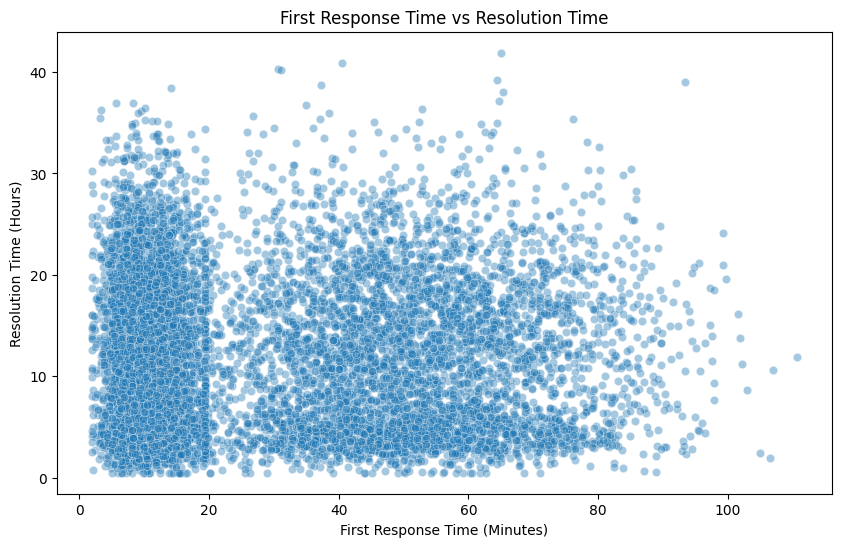

In [54]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x='First_Response_Minutes',
    y='Resolution_Time_Hours',
    alpha=0.4
)

plt.title('First Response Time vs Resolution Time')
plt.xlabel('First Response Time (Minutes)')
plt.ylabel('Resolution Time (Hours)')
plt.show()

There is no clear upward or downward pattern in the points. The points are spread widely across the chart, which is consistent with the correlation of -0.0014, essentially zero.



### Insight

The correlation between First Response Time and Resolution Time was -0.0014, which is effectively zero. The scatter plot also showed no clear linear relationship between the two variables.

This indicates that faster initial responses did not necessarily result in faster overall ticket resolution in this dataset. Resolution time appears to be influenced more by factors such as issue type and ticket complexity than by first response time alone.



# Do escalated tickets take longer to resolve?

In [55]:
escalation_resolution = (
    df_clean.groupby('Escalated')['Resolution_Time_Hours']
    .agg(['mean', 'median', 'count'])
    .round(2)
)

print(escalation_resolution)

            mean  median  count
Escalated                      
No         11.62    10.7   9328
Yes        14.86    15.5    672


### Insight

Escalated tickets had a higher average resolution time of 14.86 hours compared with 11.62 hours for non-escalated tickets.

The median resolution time was also higher for escalated tickets (15.5 hours vs 10.7 hours), showing that the difference was not driven only by a small number of extreme cases.

Escalated tickets therefore appear to be associated with longer resolution times. However, this analysis does not establish that escalation itself causes delays, since more complex tickets may be both slower to resolve and more likely to be escalated.

# Do reopened tickets have lower customer satisfaction?

In [56]:
reopened_satisfaction = (
    df_clean.groupby('Reopened')['Customer_Satisfaction']
    .agg(['mean', 'median', 'count'])
    .round(2)
)

print(reopened_satisfaction)

          mean  median  count
Reopened                     
No        3.90     4.0   9391
Yes       3.78     4.0    609


### Insight

Reopened tickets had a slightly lower average customer satisfaction score of 3.78 compared with 3.90 for tickets that were not reopened.

The difference was 0.12 points on a 5-point satisfaction scale, while the median satisfaction score was 4.0 for both groups.

This suggests that reopened tickets were associated with slightly lower customer satisfaction, although the analysis does not establish that reopening directly causes lower satisfaction.

# Which issue types have the lowest customer satisfaction?

In [57]:
issue_satisfaction = (
    df_clean.groupby('Issue_Type')['Customer_Satisfaction']
    .agg(['mean', 'median', 'count'])
    .sort_values('mean')
    .round(2)
)

print(issue_satisfaction)

                 mean  median  count
Issue_Type                          
Integration      3.55     4.0   1322
Feature Request  3.65     4.0   1000
Performance      3.75     4.0   1069
Bug              3.80     4.0   1788
Data Issue       3.90     4.0    996
Payment Issue    4.07     4.0   1214
Account Setup    4.18     4.0    998
Login Issue      4.20     4.0   1613


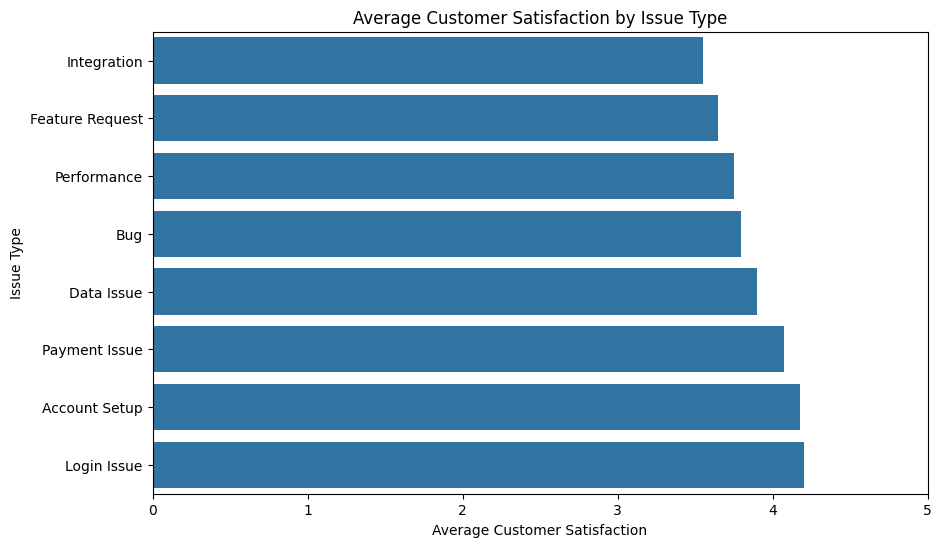

In [58]:
plt.figure(figsize=(10, 6))

satisfaction_order = (
    df_clean.groupby('Issue_Type')['Customer_Satisfaction']
    .mean()
    .sort_values()
    .index
)

sns.barplot(
    data=df_clean,
    x='Customer_Satisfaction',
    y='Issue_Type',
    order=satisfaction_order,
    estimator='mean',
    errorbar=None
)

plt.title('Average Customer Satisfaction by Issue Type')
plt.xlabel('Average Customer Satisfaction')
plt.ylabel('Issue Type')
plt.xlim(0, 5)
plt.show()

# What characteristics are associated with High-priority tickets?

In [59]:
customer_priority = pd.crosstab(
    df_clean['Customer_Type'],
    df_clean['Priority'],
    normalize='index'
).mul(100).round(2)

print(customer_priority)

Priority       High    Low  Medium
Customer_Type                     
Enterprise     7.70  62.28   30.03
Individual     3.46  78.10   18.44
SMB            2.99  78.50   18.51
Startup        2.74  79.88   17.38


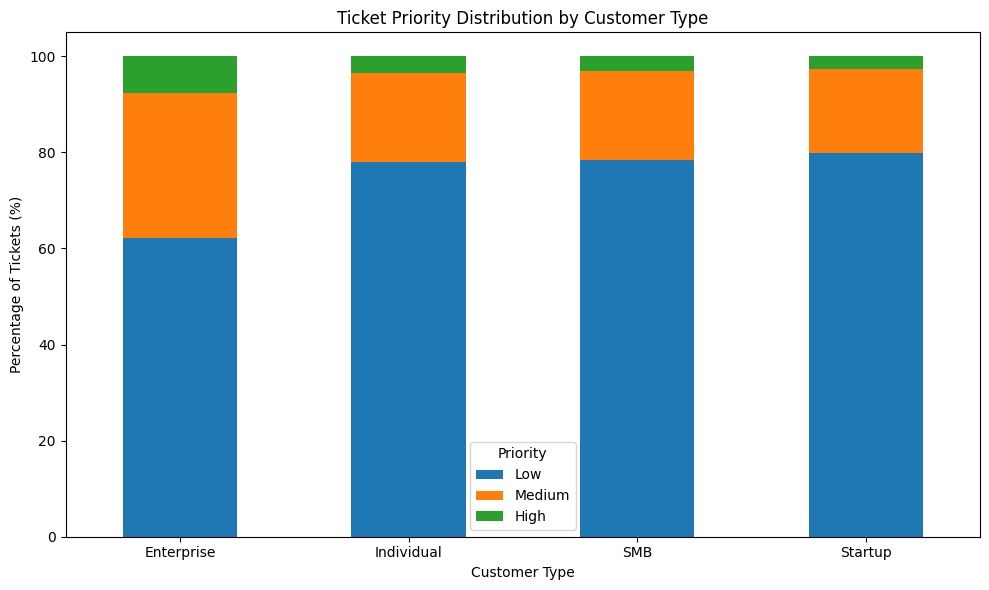

In [60]:
customer_priority = pd.crosstab(
    df_clean['Customer_Type'],
    df_clean['Priority'],
    normalize='index'
).mul(100)

# Keep priority categories in a consistent order
customer_priority = customer_priority[['Low', 'Medium', 'High']]

customer_priority.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Ticket Priority Distribution by Customer Type')
plt.xlabel('Customer Type')
plt.ylabel('Percentage of Tickets (%)')
plt.xticks(rotation=0)
plt.legend(title='Priority')
plt.tight_layout()
plt.show()

### Insight

Enterprise customers had the highest proportion of High-priority tickets at 7.70%, compared with 3.46% for Individual customers, 2.99% for SMB customers, and 2.74% for Startup customers.

Enterprise customers also had a higher proportion of Medium-priority tickets. This suggests that customer type may be a useful factor when analysing ticket priority. However, customer type alone does not determine ticket priority.

# Which products receive more high-priority tickets?

In [61]:

# Calculate priority distribution for each product
product_priority = pd.crosstab(
    df_clean['Product'],
    df_clean['Priority'],
    normalize='index'
).mul(100)

# Display priority percentages
product_priority = product_priority[['Low', 'Medium', 'High']]
print(product_priority.round(2))


Priority         Low  Medium  High
Product                           
API            75.28   20.22  4.49
Analytics      75.68   20.54  3.78
Billing        76.14   20.21  3.65
CRM            74.68   20.83  4.49
Collaboration  74.87   21.60  3.53


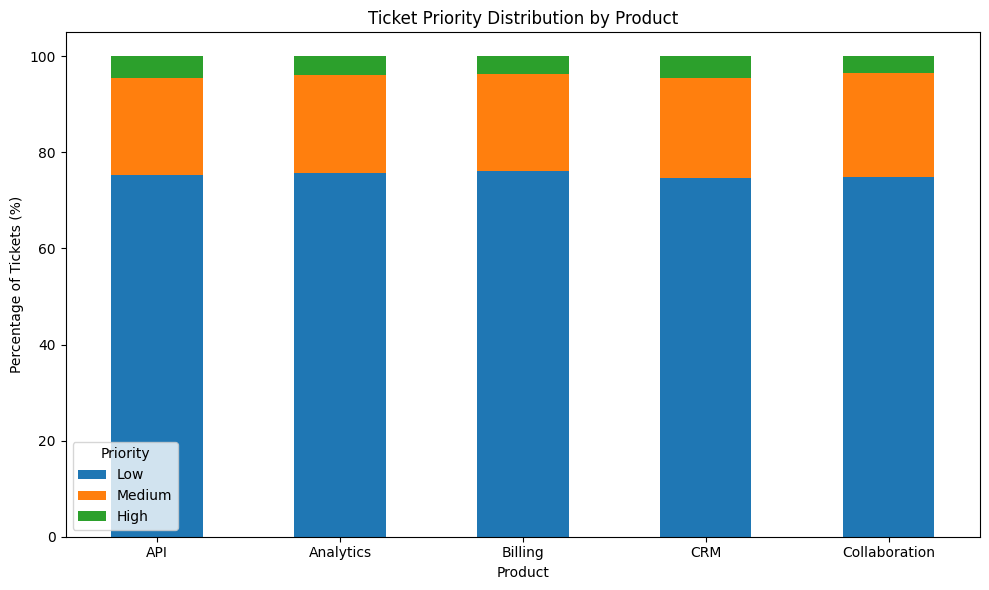

In [62]:

product_priority.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Ticket Priority Distribution by Product')
plt.xlabel('Product')
plt.ylabel('Percentage of Tickets (%)')
plt.xticks(rotation=0)
plt.legend(title='Priority')
plt.tight_layout()
plt.show()


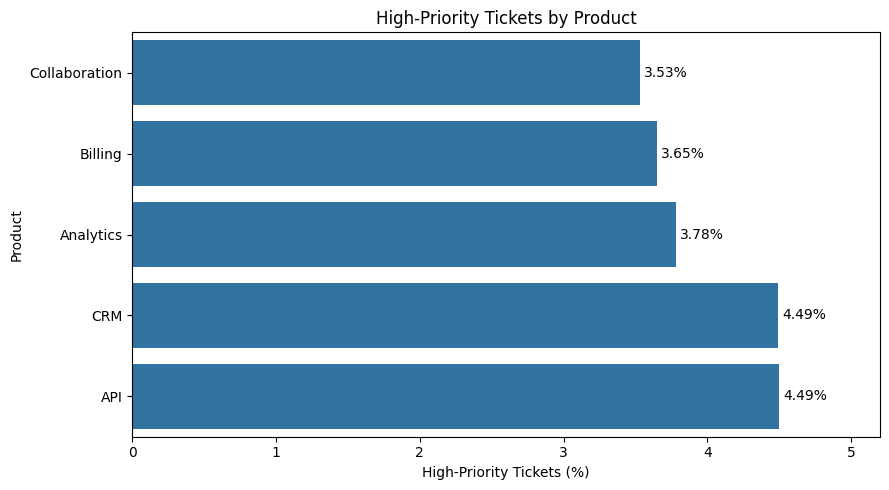

In [63]:

high_priority = (
    product_priority['High']
    .sort_values(ascending=True)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=high_priority.values,
    y=high_priority.index,
    errorbar=None
)

plt.title('High-Priority Tickets by Product')
plt.xlabel('High-Priority Tickets (%)')
plt.ylabel('Product')

# Show the percentage beside each bar
for i, value in enumerate(high_priority.values):
    plt.text(value + 0.03, i, f'{value:.2f}%', va='center')

plt.xlim(0, 5.2)
plt.tight_layout()
plt.show()


In [64]:

channel_priority = pd.crosstab(
    df_clean['Channel'],
    df_clean['Priority'],
    normalize='index'
).mul(100)

channel_priority = channel_priority[['Low', 'Medium', 'High']]

print(channel_priority.round(2))


Priority    Low  Medium  High
Channel                      
Chat      75.71   20.44  3.85
Email     75.50   20.23  4.28
Phone     74.79   21.04  4.18
Web Form  74.50   21.90  3.60


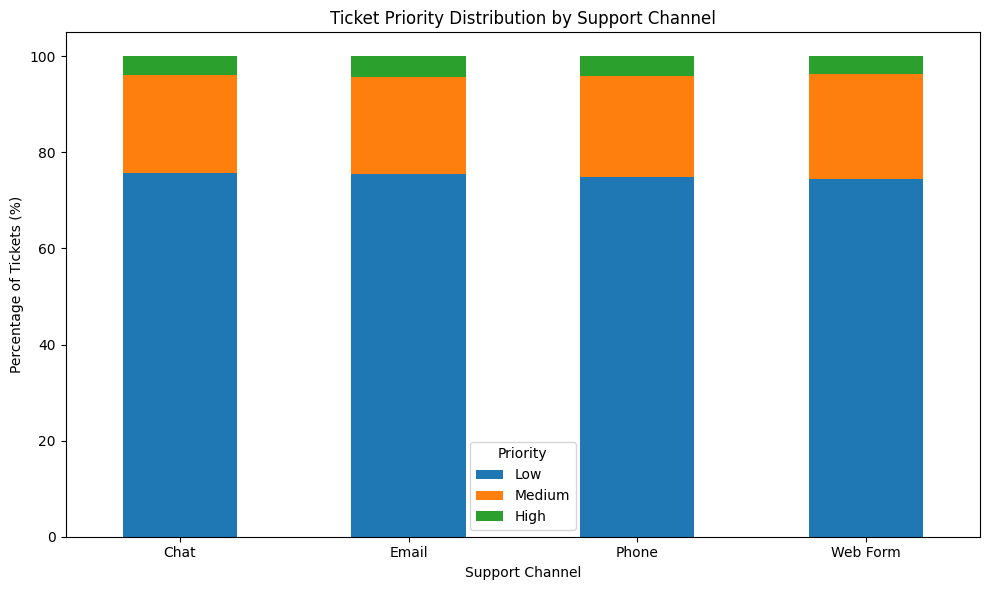

In [65]:

channel_priority.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Ticket Priority Distribution by Support Channel')
plt.xlabel('Support Channel')
plt.ylabel('Percentage of Tickets (%)')
plt.xticks(rotation=0)
plt.legend(title='Priority')
plt.tight_layout()
plt.show()


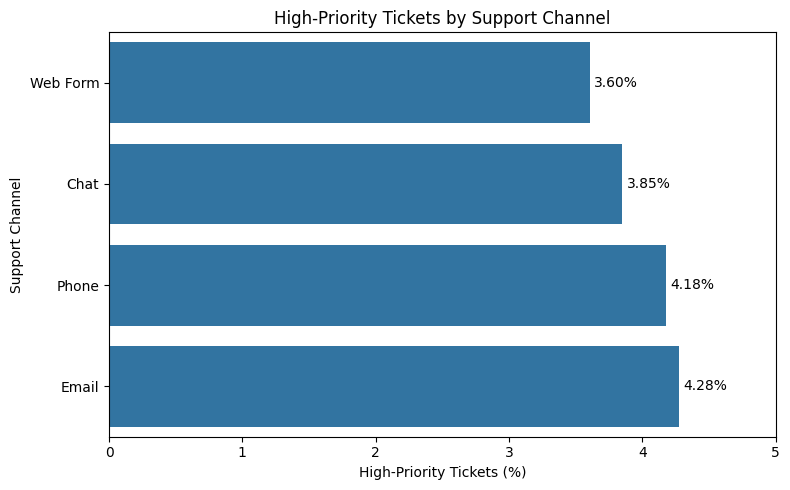

In [66]:

high_priority_channel = (
    channel_priority['High']
    .sort_values(ascending=True)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=high_priority_channel.values,
    y=high_priority_channel.index,
    errorbar=None
)

plt.title('High-Priority Tickets by Support Channel')
plt.xlabel('High-Priority Tickets (%)')
plt.ylabel('Support Channel')

for i, value in enumerate(high_priority_channel.values):
    plt.text(value + 0.03, i, f'{value:.2f}%', va='center')

plt.xlim(0, 5)
plt.tight_layout()
plt.show()



## Business Insights

1. **Integration issues need attention:** They had the longest average resolution time at 19.92 hours, the lowest average customer satisfaction at 3.55/5, and the highest High-priority ticket rate at 7.87%.

2. **Bug and Login issues have high ticket volumes:** Together, they accounted for approximately 34% of all tickets. This makes them useful areas for further investigation, although volume alone does not indicate severity.

3. **Enterprise customers had a higher High-priority ticket share:** 7.70% of Enterprise tickets were High priority, compared with 2.99% for SMB and 2.74% for Startup customers.

4. **Escalated tickets took longer to resolve:** Their average resolution time was 14.86 hours, compared with 11.62 hours for non-escalated tickets. This is an association, not proof that escalation causes delays.

5. **Reopened tickets had slightly lower satisfaction:** Their average satisfaction was 3.78/5, compared with 3.90/5 for tickets that were not reopened.


# Machine Learning

In [67]:

# Create a separate copy for Machine Learning
df_ml = df_clean.copy()

# Extract useful information from the ticket creation date
df_ml['Created_Hour'] = df_ml['Created_Date'].dt.hour
df_ml['Created_DayOfWeek'] = df_ml['Created_Date'].dt.dayofweek
df_ml['Created_Month'] = df_ml['Created_Date'].dt.month

# Select features available when a ticket is created
features = [
    'Customer_Type',
    'Product',
    'Issue_Type',
    'Channel',
    'Customer_Tenure_Months',
    'Previous_Tickets',
    'Created_Hour',
    'Created_DayOfWeek',
    'Created_Month'
]

# Define X (input features) and y (target)
X = df_ml[features]
y = df_ml['Priority']

# Check the dataset
print("Feature dataset shape:", X.shape)
print("\nTarget distribution:")
print(y.value_counts())
print("\nTarget distribution in percentage:")
print((y.value_counts(normalize=True) * 100).round(2))
print("\nMissing values in features:", X.isnull().sum().sum())


Feature dataset shape: (10000, 9)

Target distribution:
Priority
Low       7527
Medium    2070
High       403
Name: count, dtype: int64

Target distribution in percentage:
Priority
Low       75.27
Medium    20.70
High       4.03
Name: proportion, dtype: float64

Missing values in features: 0


In [68]:

from sklearn.model_selection import train_test_split

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining priority distribution (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting priority distribution (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))


Training features: (8000, 9)
Testing features: (2000, 9)

Training priority distribution (%):
Priority
Low       75.28
Medium    20.70
High       4.03
Name: proportion, dtype: float64

Testing priority distribution (%):
Priority
Low       75.25
Medium    20.70
High       4.05
Name: proportion, dtype: float64


In [69]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Separate categorical and numerical columns
categorical_features = [
    'Customer_Type',
    'Product',
    'Issue_Type',
    'Channel'
]

numerical_features = [
    'Customer_Tenure_Months',
    'Previous_Tickets',
    'Created_Hour',
    'Created_DayOfWeek',
    'Created_Month'
]

# Convert categorical columns into numerical features
preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        ),
        ('numerical', 'passthrough', numerical_features)
    ]
)

# Build the model pipeline
rf_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'classifier',
            RandomForestClassifier(
                n_estimators=200,
                class_weight='balanced',
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model training completed!")


Random Forest model training completed!


Model Evaluation

In [70]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Predict priorities for unseen test tickets
y_pred = rf_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.2%}")

# Detailed evaluation for each priority
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion matrix
labels = ['High', 'Low', 'Medium']

cm = confusion_matrix(y_test, y_pred, labels=labels)

print("\nConfusion Matrix (Actual rows, Predicted columns):")
print(pd.DataFrame(
    cm,
    index=[f'Actual {label}' for label in labels],
    columns=[f'Predicted {label}' for label in labels]
))


Model Accuracy: 75.05%

Classification Report:
              precision    recall  f1-score   support

        High       0.00      0.00      0.00        81
         Low       0.76      0.98      0.86      1505
      Medium       0.42      0.06      0.11       414

    accuracy                           0.75      2000
   macro avg       0.39      0.35      0.32      2000
weighted avg       0.66      0.75      0.67      2000


Confusion Matrix (Actual rows, Predicted columns):
               Predicted High  Predicted Low  Predicted Medium
Actual High                 0             75                 6
Actual Low                  0           1476                29
Actual Medium               0            389                25


In [71]:

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# Split the training data into a smaller training set
# and a validation set
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Model 1: Standard balanced weights
model_balanced = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

# Model 2: Give more weight to High-priority tickets
model_high_weight = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        class_weight={
            'Low': 1,
            'Medium': 2,
            'High': 10
        },
        random_state=42,
        n_jobs=-1
    ))
])

# Train and evaluate both using the validation set
for name, model in [
    ('Balanced Weights', model_balanced),
    ('Higher High-Priority Weight', model_high_weight)
]:
    model.fit(X_subtrain, y_subtrain)
    val_pred = model.predict(X_val)

    print(f'\n===== {name} =====')
    print(classification_report(
        y_val,
        val_pred,
        labels=['High', 'Low', 'Medium'],
        zero_division=0
    ))



===== Balanced Weights =====
              precision    recall  f1-score   support

        High       0.00      0.00      0.00        65
         Low       0.76      0.98      0.86      1204
      Medium       0.26      0.03      0.05       331

    accuracy                           0.75      1600
   macro avg       0.34      0.34      0.30      1600
weighted avg       0.62      0.75      0.65      1600


===== Higher High-Priority Weight =====
              precision    recall  f1-score   support

        High       0.00      0.00      0.00        65
         Low       0.76      0.98      0.86      1204
      Medium       0.22      0.02      0.04       331

    accuracy                           0.74      1600
   macro avg       0.33      0.34      0.30      1600
weighted avg       0.62      0.74      0.65      1600



In [72]:

# Check High-priority percentage for each category
categorical_columns = [
    'Customer_Type',
    'Product',
    'Issue_Type',
    'Channel'
]

for col in categorical_columns:
    high_rate = (
        df_clean.groupby(col)['Priority']
        .apply(lambda s: (s == 'High').mean() * 100)
        .sort_values(ascending=False)
    )

    print(f'\nHigh-priority rate by {col} (%)')
    print(high_rate.round(2))



High-priority rate by Customer_Type (%)
Customer_Type
Enterprise    7.70
Individual    3.46
SMB           2.99
Startup       2.74
Name: Priority, dtype: float64

High-priority rate by Product (%)
Product
API              4.49
CRM              4.49
Analytics        3.78
Billing          3.65
Collaboration    3.53
Name: Priority, dtype: float64

High-priority rate by Issue_Type (%)
Issue_Type
Integration        7.87
Feature Request    7.20
Bug                6.77
Performance        4.86
Data Issue         3.01
Payment Issue      1.32
Login Issue        0.37
Account Setup      0.20
Name: Priority, dtype: float64

High-priority rate by Channel (%)
Channel
Email       4.28
Phone       4.18
Chat        3.85
Web Form    3.60
Name: Priority, dtype: float64


In [73]:

numeric_columns = [
    'Customer_Tenure_Months',
    'Previous_Tickets'
]

print(
    df_clean.groupby('Priority')[numeric_columns]
    .mean()
    .round(2)
)


          Customer_Tenure_Months  Previous_Tickets
Priority                                          
High                       24.32              4.71
Low                        25.02              3.84
Medium                     25.29              4.21


Model Evaluation

In [74]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix

# Create the Decision Tree pipeline
dt_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        max_depth=6,
        min_samples_leaf=20,
        class_weight='balanced',
        random_state=42
    ))
])

# Train using the sub-training data
dt_model.fit(X_subtrain, y_subtrain)

# Predict on the validation set
dt_val_pred = dt_model.predict(X_val)

# Evaluate the model
print("Decision Tree Classification Report:")
print(classification_report(
    y_val,
    dt_val_pred,
    labels=['High', 'Low', 'Medium'],
    zero_division=0
))

print("Confusion Matrix:")
print(pd.DataFrame(
    confusion_matrix(
        y_val,
        dt_val_pred,
        labels=['High', 'Low', 'Medium']
    ),
    index=['Actual High', 'Actual Low', 'Actual Medium'],
    columns=['Predicted High', 'Predicted Low', 'Predicted Medium']
))


Decision Tree Classification Report:
              precision    recall  f1-score   support

        High       0.14      0.46      0.21        65
         Low       0.89      0.48      0.62      1204
      Medium       0.25      0.55      0.34       331

    accuracy                           0.49      1600
   macro avg       0.42      0.50      0.39      1600
weighted avg       0.73      0.49      0.55      1600

Confusion Matrix:
               Predicted High  Predicted Low  Predicted Medium
Actual High                30              7                28
Actual Low                102            572               530
Actual Medium              85             64               182


In [75]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
import pandas as pd

results = []

# Test different tree complexity settings
for depth in [3, 4, 6, 8, 10]:
    for leaf_size in [10, 20, 40]:

        model = Pipeline([
            ('preprocessor', preprocessor),
            ('classifier', DecisionTreeClassifier(
                max_depth=depth,
                min_samples_leaf=leaf_size,
                class_weight='balanced',
                random_state=42
            ))
        ])

        model.fit(X_subtrain, y_subtrain)
        predictions = model.predict(X_val)

        results.append({
            'Max_Depth': depth,
            'Min_Samples_Leaf': leaf_size,
            'Accuracy': accuracy_score(y_val, predictions),
            'High_Precision': precision_score(
                y_val, predictions,
                labels=['High'],
                average='macro',
                zero_division=0
            ),
            'High_Recall': recall_score(
                y_val, predictions,
                labels=['High'],
                average='macro',
                zero_division=0
            ),
            'Macro_F1': f1_score(
                y_val, predictions,
                average='macro',
                zero_division=0
            )
        })

results_df = pd.DataFrame(results)

print(
    results_df.sort_values(
        'Macro_F1', ascending=False
    ).round(3).to_string(index=False)
)


 Max_Depth  Min_Samples_Leaf  Accuracy  High_Precision  High_Recall  Macro_F1
         6                20     0.490           0.138        0.462     0.391
         6                10     0.491           0.134        0.462     0.390
         6                40     0.484           0.139        0.446     0.389
         8                40     0.454           0.088        0.477     0.357
        10                10     0.472           0.076        0.431     0.354
        10                40     0.454           0.081        0.431     0.353
         8                10     0.457           0.067        0.400     0.349
         8                20     0.453           0.077        0.477     0.349
        10                20     0.449           0.078        0.477     0.346
         3                40     0.377           0.063        0.938     0.248
         4                40     0.369           0.063        0.954     0.248
         3                10     0.374           0.063        0.


## Conclusion

This project analysed 10,000 customer support tickets to understand issue patterns, resolution time, priority levels, escalations, and customer satisfaction.

The analysis highlighted Integration issues as an area that needs further investigation because they had the longest resolution time and lowest average satisfaction.

I also experimented with Random Forest and Decision Tree models to predict ticket priority. The results showed that predicting High-priority tickets was challenging because they represented only around 4% of the dataset. The Random Forest model failed to identify High-priority tickets, while the Decision Tree identified some but also produced many false positives.

The current models are experimental and should not be used for real support decisions without further improvement and validation.

### Future Improvements

- Explore additional features that are available when a ticket is created.
- Investigate class imbalance and test other classification approaches.
- Improve High-priority prediction while balancing missed urgent tickets against false alerts.
- Validate the model on additional or more recent ticket data.
